# E-commerce Product Classification Using Word Embeddings (Submission 2)

**Objective.** Extend Submission 1 (TF-IDF) with **word embeddings**. We classify product descriptions into the same four categories (Electronics, Household, Books, Clothing & Accessories) and compare:

1. the three **TF-IDF models** of Submission 1 (Naive Bayes, Logistic Regression, Linear SVM),
2. **GloVe - Frozen**: pretrained GloVe vectors that are *not* changed during training,
3. **GloVe - Fine-Tuned**: the same model, but the GloVe vectors are *updated* on our e-commerce data.

**Same methodology as Submission 1.** Same data loading, same cleaning (`prepare_dataframe`), same stratified 80/20 split with `RANDOM_SEED = 42`, same test set, same metrics. This makes all five results directly comparable.

**Model (deliberately simple).** `Embedding layer -> average of the word vectors -> Dense layer (4 classes)`. No recurrent or convolutional layers.

> All numbers, tables and figures are produced by the code cells when they run. No result is typed in by hand.

## 0. Setup
The cell makes the project modules importable (it works from the project root or from `notebooks/`) and imports the libraries. `embeddings.py` contains the new Submission 2 code; everything else is reused from Submission 1.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # hide TensorFlow start-up messages
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"    # more identical results on different computers
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

import config
from src import data_loader, embeddings, evaluate, preprocessing, train
from src.preprocessing import clean_text

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 150)
warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_SEED = config.RANDOM_SEED
print("Project root:", ROOT)

Project root: /home/claude/ecommerce-product-classification


## 1. Dataset Loading
Identical to Submission 1: the loader detects the header, the text column and the label column. If the file is missing, run `python main.py --download` or copy `ecommerceDataset.csv` into `data/`.

In [2]:
data_path = data_loader.find_dataset()
if data_path is None:
    raise SystemExit(data_loader.missing_dataset_message())

raw_df, TEXT_COL, LABEL_COL = data_loader.load_dataset(data_path)
print(f"File: {data_path.name} | text column: '{TEXT_COL}' | label column: '{LABEL_COL}'")

File: ecommerceDataset.csv | text column: 'text' | label column: 'label'


## 2. Data Exploration
First rows, shape, column names, data types and summary statistics of the raw data.

In [3]:
display(raw_df.head(5).assign(text=lambda d: d[TEXT_COL].astype(str).str.slice(0, 150) + " ..."))
print("Shape        :", raw_df.shape)
print("Column names :", list(raw_df.columns))
display(raw_df.dtypes.to_frame("dtype"))
display(raw_df.describe(include="all"))

,label,text
0,Household,Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting mad...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x 10 inch, Special Effect UV Print Textured, SAO297) Painting made up in..."
2,Household,"SAF 'UV Textured Modern Art Print Framed' Painting (Synthetic, 35 cm x 50 cm x 3 cm, Set of 3) Color:Multicolor ..."
3,Household,"SAF Flower Print Framed Painting (Synthetic, 13.5 inch x 22 inch, UV Textured, Set of 3, SANFSW4951) Color:Multicolo..."
4,Household,Incredible Gifts India Wooden Happy Birthday Unique Personalized Gift (5 X 4 Inch) Size:4 x 5 Made Of Natural Impo...


Shape        : (50425, 2)
Column names : ['label', 'text']


,dtype
label,str
text,str


,label,text
count,50425,50424
unique,4,27802
top,Household,"Think & Grow Rich About the Author NAPOLEON HILL, born in Pound, Southwest Virginia in 1883, was a very successful A..."
freq,19313,30


## 3. Missing Values and Duplicate Analysis
As in Submission 1, missing descriptions or labels are removed, and **exact duplicate records** are removed so that the same text cannot appear in both the training and the test set (data leakage).

In [4]:
overview = preprocessing.dataset_overview(raw_df)
missing = pd.DataFrame({"missing values": overview["missing_per_column"]})
missing["percent"] = (100 * missing["missing values"] / len(raw_df)).round(4)
display(missing)
n_dup = overview["duplicate_rows"]
print(f"Exact duplicate rows: {n_dup:,} of {len(raw_df):,} ({100 * n_dup / len(raw_df):.1f}%)")
display(raw_df[LABEL_COL].value_counts().to_frame("samples (before cleaning)"))

,missing values,percent
label,0,0.000
text,1,0.002


Exact duplicate rows: 22,622 of 50,425 (44.9%)


,samples (before cleaning)
label,
Household,19313
Books,11820
Electronics,10621
Clothing & Accessories,8671


## 4. Data Cleaning and Preprocessing
The same function `prepare_dataframe` is used (HTML tags, URLs and extra whitespace removed, lowercase, punctuation replaced by spaces, numbers kept). Every removal is counted.

In [5]:
df, data_report = preprocessing.prepare_dataframe(raw_df, TEXT_COL, LABEL_COL)
removals = pd.Series({
    "missing label": data_report["removed_missing_label"],
    "missing / blank description": data_report["removed_missing_text"],
    "unexpected label": data_report["removed_unexpected_label"],
    "exact duplicate records": data_report["removed_exact_duplicates"],
    "empty after cleaning": data_report["removed_empty_after_cleaning"],
    "duplicates after cleaning": data_report["removed_duplicates_after_cleaning"],
    "identical text, conflicting labels": data_report["removed_conflicting_labels"],
}, name="rows removed")
display(removals.to_frame())
print(f"Rows before: {data_report['rows_initial']:,}  rows after: {data_report['rows_final']:,}  "
      f"removed: {data_report['rows_removed_total']:,} ({data_report['percent_removed']}%)")
if data_report["missing_categories"]:
    print("WARNING - categories missing from the data:", data_report["missing_categories"])
LABELS = preprocessing.present_categories(df["label"])
print("Categories used:", LABELS)

,rows removed
missing label,0
missing / blank description,1
unexpected label,0
exact duplicate records,22622
empty after cleaning,0
duplicates after cleaning,93
"identical text, conflicting labels",0


Rows before: 50,425  rows after: 27,709  removed: 22,716 (45.05%)
Categories used: ['Electronics', 'Household', 'Books', 'Clothing & Accessories']


## 5. Class Distribution
Number of samples per category after cleaning (table and bar chart).

,samples,percent
label,,
Electronics,5302,19.13
Household,10558,38.10
Books,6202,22.38
Clothing & Accessories,5647,20.38


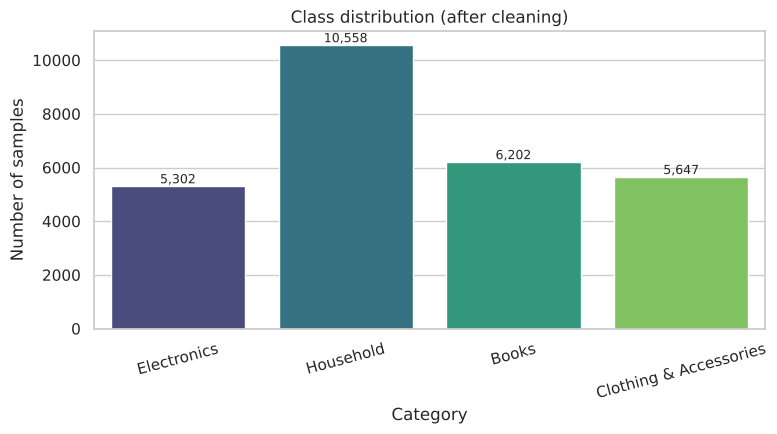

Words per cleaned description:


,words
count,27709.0
mean,115.0
std,169.8
min,1.0
25%,35.0
50%,78.0
75%,150.0
max,8427.0


75.0% of the descriptions have at most 150 words (MAX_LEN = 150); longer ones are cut after 150 words.


In [6]:
counts = df["label"].value_counts().reindex(LABELS)
display(pd.DataFrame({"samples": counts, "percent": (100 * counts / counts.sum()).round(2)}))
fig = evaluate.plot_class_distribution(counts, title="Class distribution (after cleaning)")
plt.show()
words_per_text = df["clean_text"].str.split().str.len()
print("Words per cleaned description:")
display(words_per_text.describe().round(1).to_frame("words"))
print(f"{(words_per_text <= config.MAX_LEN).mean():.1%} of the descriptions have at most {config.MAX_LEN} words "
      f"(MAX_LEN = {config.MAX_LEN}); longer ones are cut after {config.MAX_LEN} words.")

## 6. Train-Test Split
**Exactly the same call as in Submission 1** (`train.split_data`, 80/20, stratified, seed 42). Therefore the training and test sets are identical, and the results of all models can be compared fairly. The raw text is split first; then the same `clean_text` function is applied.

In [7]:
X_train, X_test, y_train, y_test = train.split_data(df, config.TEST_SIZE, RANDOM_SEED)
print(f"Training samples: {len(X_train):,}   Test samples: {len(X_test):,}   (seed = {RANDOM_SEED})")

X_train_clean = X_train.map(clean_text)      # same cleaning function as in Submission 1
X_test_clean = X_test.map(clean_text)
pd.DataFrame({"train %": (100 * y_train.value_counts(normalize=True)).round(2),
              "test %": (100 * y_test.value_counts(normalize=True)).round(2)}).reindex(LABELS)

Training samples: 22,167   Test samples: 5,542   (seed = 42)


,train %,test %
label,,
Electronics,19.14,19.13
Household,38.10,38.11
Books,22.38,22.39
Clothing & Accessories,20.38,20.37


## 7. Text Representation with GloVe Word Embeddings

**TF-IDF (Submission 1)** gives every word its own column. Words are unrelated: *charger* and *adapter* are as different as *charger* and *novel*. The vector is very long (50,000 numbers) and mostly zeros.

**A word embedding** represents each word by a short list of numbers (here **100**). Words used in similar contexts get similar vectors, so *charger* and *adapter* end up close to each other.

**GloVe** (*Global Vectors*, Stanford) learned such vectors from about 6 billion words of Wikipedia and news text (`glove.6B.100d`: 400,000 words x 100 numbers). We reuse them as *pretrained* knowledge.

**From text to one vector (what our model does):**
1. Each word of the description is replaced by its number in a vocabulary.
2. The *Embedding layer* looks up the 100-number vector of each word.
3. **Average pooling** takes the mean of all word vectors, giving one 100-number vector per description.
4. One **Dense layer** with 4 outputs and *softmax* turns this vector into four class probabilities (this is multinomial logistic regression on the averaged vector).

**Frozen vs fine-tuned.** In the *frozen* model the GloVe vectors are never changed; only the final Dense layer (404 numbers) is learned. In the *fine-tuned* model the same architecture is used, but the 100-number vectors are also updated during training (about 2 million numbers), so they adapt to e-commerce language.

**No data leakage.** As with TF-IDF, the vocabulary is built **from the training texts only**. Words that appear only in the test set become the *unknown* word. Words that GloVe does not contain get a zero vector (they are ignored by the frozen model and can be learned by the fine-tuned model).

The cell below downloads GloVe the first time (about 130 MB, stored in `data/glove/`).

In [8]:
glove_path = embeddings.download_glove()
print("GloVe file:", glove_path.name, f"({glove_path.stat().st_size / 1e6:.0f} MB)")

word_index = embeddings.build_vocabulary(X_train_clean)                  # training texts only
glove_vectors = embeddings.load_glove_vectors(glove_path, word_index)
embedding_matrix = embeddings.build_embedding_matrix(word_index, glove_vectors)

X_train_seq = embeddings.texts_to_sequences(X_train_clean, word_index)
X_test_seq = embeddings.texts_to_sequences(X_test_clean, word_index)
class_to_id = {name: i for i, name in enumerate(LABELS)}
y_train_id = y_train.map(class_to_id).values

tokens = [w for text in X_train_clean for w in text.split()]
print(f"Vocabulary size           : {len(word_index):,} words (+ padding and unknown)")
print(f"Vocabulary words in GloVe : {len(glove_vectors):,} ({100 * len(glove_vectors) / len(word_index):.1f}%)")
print(f"Share of training word occurrences covered by the vocabulary: "
      f"{np.mean([w in word_index for w in tokens]):.1%}")
print(f"Embedding matrix shape    : {embedding_matrix.shape}  (words x 100)")
print(f"Sequences                 : train {X_train_seq.shape}, test {X_test_seq.shape}  (texts x MAX_LEN)")

GloVe file: glove.6B.100d.txt (347 MB)


Vocabulary size           : 19,998 words (+ padding and unknown)
Vocabulary words in GloVe : 18,004 (90.0%)


Share of training word occurrences covered by the vocabulary: 96.5%
Embedding matrix shape    : (20000, 100)  (words x 100)
Sequences                 : train (22167, 150), test (5542, 150)  (texts x MAX_LEN)


In [9]:
# Illustrative demonstration (made-up sentence, not a dataset record)
demo = clean_text("Wireless charger for phone, 20W!")
demo_numbers = [word_index.get(w, embeddings.UNKNOWN) for w in demo.split()]
print("Cleaned text   :", demo)
print("Word numbers   :", demo_numbers)
print("Padded sequence:", embeddings.texts_to_sequences([demo], word_index)[0][:12], "... (zeros up to length", config.MAX_LEN, ")")
vec = embedding_matrix[word_index["wireless"]]
print("\nGloVe vector of 'wireless' (first 8 of 100 numbers):", vec[:8].round(3))

def nearest_words(word, matrix, n=6):
    # words whose vector points in the most similar direction (cosine similarity)
    unit = matrix / np.maximum(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-9)
    scores = unit @ unit[word_index[word]]
    id_to_word = {i: w for w, i in word_index.items()}
    best = [i for i in np.argsort(-scores) if i >= 2 and i != word_index[word]][:n]
    return [id_to_word[i] for i in best]

glove_neighbours = {w: nearest_words(w, embedding_matrix) for w in ["charger", "novel", "cotton", "cooker"] if w in word_index}
pd.DataFrame(glove_neighbours, index=[f"neighbour {i}" for i in range(1, 7)]).T

Cleaned text   : wireless charger for phone 20w
Word numbers   : [210, 632, 7, 201, 11992]
Padded sequence: [  210   632     7   201 11992     0     0     0     0     0     0     0] ... (zeros up to length 150 )

GloVe vector of 'wireless' (first 8 of 100 numbers): [ 0.126 -0.043  0.351  0.251  0.588 -0.61  -0.235 -0.554]


,neighbour 1,neighbour 2,neighbour 3,neighbour 4,neighbour 5,neighbour 6
charger,rechargeable,turbo,battery,ipod,rx,laptop
novel,novels,fiction,book,adaptation,story,author
cotton,wool,wheat,corn,silk,textile,grain
cooker,cookers,stove,casserole,oven,fridge,quart


## 8. Model Development

### 8.1 The model
Both GloVe models use **exactly the same architecture and settings**; the only difference is `trainable`.

In [10]:
import inspect
print(inspect.getsource(embeddings.build_model))
frozen_demo = embeddings.build_model(embedding_matrix, len(LABELS), trainable=False)
frozen_demo.summary()

def build_model(embedding_matrix, n_classes, trainable):
    """Embedding -> average pooling -> Dense. `trainable=False` freezes GloVe, `True` fine-tunes it."""
    keras.utils.set_random_seed(config.RANDOM_SEED)
    model = keras.Sequential([
        keras.Input(shape=(config.MAX_LEN,)),
        layers.Embedding(input_dim=embedding_matrix.shape[0], output_dim=config.EMBEDDING_DIM,
                         embeddings_initializer=keras.initializers.Constant(embedding_matrix),
                         mask_zero=True,            # padding is ignored when averaging
                         trainable=trainable),
        layers.GlobalAveragePooling1D(),            # average of the word vectors = one vector per text
        layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(config.LEARNING_RATE),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 100)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 100)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           404 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,404 (7.63 MB)

 Trainable params: 404 (1.58 KB)

 Non-trainable params: 2,000,000 (7.63 MB)

Settings (from `config.py`, same for both models): 100-dimensional GloVe, vocabulary of 20,000 words, 150 words per text, **10 epochs**, batch size 64, Adam optimiser with learning rate **0.003**, loss `sparse_categorical_crossentropy`. `mask_zero=True` makes the average ignore the padding.

### 8.2 Diagnostic run on validation data (not used for the final results)
To check the settings we train both models once while watching a **validation slice of the training data** (10%). The **test set is not touched**. We look for signs of under- or over-fitting. The learning rate and the number of epochs were chosen this way before the final evaluation.

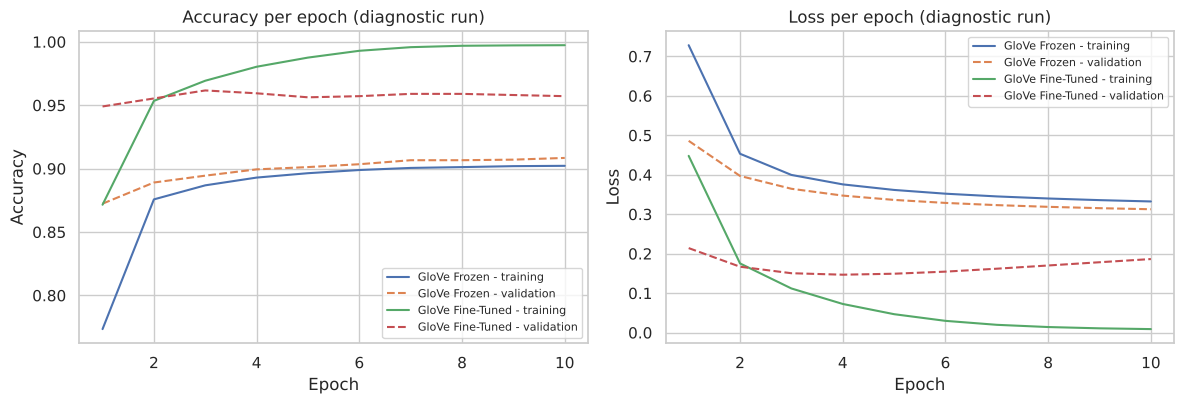

In [11]:
diagnostic = {}
for name, trainable in [("GloVe Frozen", False), ("GloVe Fine-Tuned", True)]:
    model = embeddings.build_model(embedding_matrix, len(LABELS), trainable)
    history, seconds = embeddings.train_model(model, X_train_seq, y_train_id, validation_split=0.1)
    diagnostic[name] = history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, h in diagnostic.items():
    axes[0].plot(range(1, len(h["accuracy"]) + 1), h["accuracy"], label=f"{name} - training")
    axes[0].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], "--", label=f"{name} - validation")
    axes[1].plot(range(1, len(h["loss"]) + 1), h["loss"], label=f"{name} - training")
    axes[1].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], "--", label=f"{name} - validation")
axes[0].set(title="Accuracy per epoch (diagnostic run)", xlabel="Epoch", ylabel="Accuracy")
axes[1].set(title="Loss per epoch (diagnostic run)", xlabel="Epoch", ylabel="Loss")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig(config.OUTPUTS_DIR / "embeddings_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**What the curves show.** The frozen model learns slowly and its training and validation curves stay close together; it is limited by having only 404 numbers to learn. The fine-tuned model reaches a high validation accuracy within a few epochs, but its training loss keeps falling while its validation loss starts to rise after about epoch 4. This is a mild sign of overfitting, although the validation accuracy stays roughly constant. We keep **one common setting (10 epochs)** for both models so that they remain comparable; early stopping would be a possible improvement.

### 8.3 Final training on the full training set
Now both models are trained on **all** training samples (the same 22k texts the TF-IDF models of Submission 1 saw) and evaluated later on the untouched test set. Training time is measured with the wall clock on this CPU.

In [12]:
glove_models, glove_seconds, glove_histories = {}, {}, {}
for name, trainable in [("GloVe Frozen", False), ("GloVe Fine-Tuned", True)]:
    model = embeddings.build_model(embedding_matrix, len(LABELS), trainable)
    history, seconds = embeddings.train_model(model, X_train_seq, y_train_id)
    glove_models[name], glove_seconds[name], glove_histories[name] = model, seconds, history.history
    n_params = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f"{name:18s} trainable numbers: {n_params:>9,}   training time: {seconds:6.1f} s   "
          f"final training accuracy: {history.history['accuracy'][-1]:.4f}")

GloVe Frozen       trainable numbers:       404   training time:   12.5 s   final training accuracy: 0.9036


GloVe Fine-Tuned   trainable numbers: 2,000,404   training time:   51.6 s   final training accuracy: 0.9973


### 8.4 TF-IDF models of Submission 1 (for the comparison)
The three TF-IDF pipelines are retrained with the unchanged Submission 1 code on the same split, so that the final table is produced by one single run.

In [13]:
tfidf_models, tfidf_seconds = train.train_models(X_train, y_train, seed=RANDOM_SEED)
print({name: f"{s} s" for name, s in tfidf_seconds.items()})

{'Naive Bayes': '6.3 s', 'Logistic Regression': '9.67 s', 'Linear SVM': '7.44 s'}


## 9. Model Evaluation
All models are evaluated on the **same test set** with accuracy, macro precision, macro recall and macro F1-score. (Definitions are the same as in Submission 1; the macro average gives all four classes equal weight.)

In [14]:
glove_predictions, rows = {}, []
for name, model in glove_models.items():
    y_pred = embeddings.predict_labels(model, X_test_seq, LABELS)
    glove_predictions[name] = y_pred
    rows.append({"model": name, **evaluate.compute_metrics(y_test, y_pred), "fit_seconds": glove_seconds[name]})
glove_results = pd.DataFrame(rows).set_index("model")

tfidf_results, tfidf_predictions, tfidf_reports = evaluate.evaluate_models(
    tfidf_models, X_test, y_test, LABELS, tfidf_seconds)
tfidf_results.index = "TF-IDF + " + tfidf_results.index

display(Markdown("**GloVe models (test set)**"))
display(glove_results.round(4))

**GloVe models (test set)**

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,fit_seconds
model,,,,,,,,
GloVe Frozen,0.9069,0.9129,0.9013,0.9067,0.9078,0.9069,0.9069,12.48
GloVe Fine-Tuned,0.9542,0.9557,0.9523,0.9539,0.9543,0.9542,0.9541,51.58


In [15]:
from sklearn.metrics import classification_report
for name, y_pred in glove_predictions.items():
    print("=" * 70); print(name); print("=" * 70)
    print(classification_report(y_test, y_pred, labels=LABELS, digits=4, zero_division=0))

GloVe Frozen
                        precision    recall  f1-score   support

           Electronics     0.8910    0.8481    0.8690      1060
             Household     0.8790    0.9285    0.9031      2112
                 Books     0.9453    0.9057    0.9251      1241
Clothing & Accessories     0.9362    0.9229    0.9295      1129

              accuracy                         0.9069      5542
             macro avg     0.9129    0.9013    0.9067      5542
          weighted avg     0.9078    0.9069    0.9069      5542

GloVe Fine-Tuned
                        precision    recall  f1-score   support

           Electronics     0.9333    0.9368    0.9350      1060
             Household     0.9452    0.9645    0.9548      2112
                 Books     0.9649    0.9299    0.9471      1241
Clothing & Accessories     0.9796    0.9779    0.9787      1129

              accuracy                         0.9542      5542
             macro avg     0.9557    0.9523    0.9539      5542
     

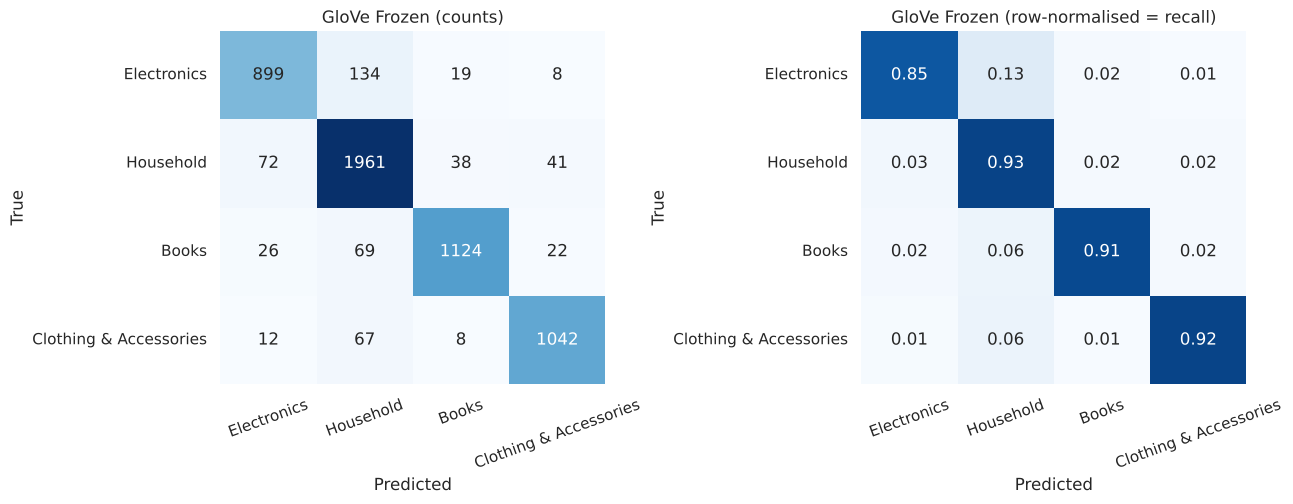

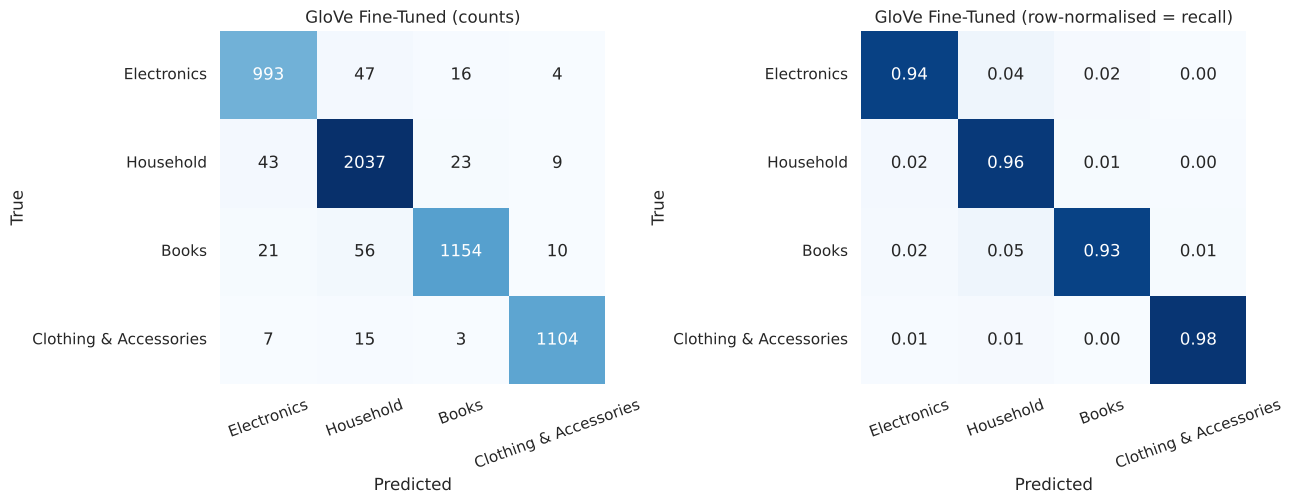

In [16]:
for name, y_pred in glove_predictions.items():
    slug = name.lower().replace(" ", "_").replace("-", "_")
    fig = evaluate.plot_confusion_matrix(y_test, y_pred, LABELS, title=name,
                                         path=config.OUTPUTS_DIR / f"embeddings_confusion_matrix_{slug}.png")
    plt.show()

## 10. Final Comparison and Best-Model Selection
The table and the bar chart compare **TF-IDF models vs. GloVe Frozen vs. GloVe Fine-Tuned**. As in Submission 1, the best model is the one with the highest **macro F1-score on the test set** (ties broken by accuracy). Training times are indicative: they depend on the computer, and the TF-IDF time includes text cleaning and vectorisation.

,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds
model,,,,,
TF-IDF + Linear SVM,0.9592,0.9606,0.9572,0.9589,7.44
TF-IDF + Logistic Regression,0.9580,0.9597,0.9553,0.9574,9.67
GloVe Fine-Tuned,0.9542,0.9557,0.9523,0.9539,51.58
TF-IDF + Naive Bayes,0.9498,0.9514,0.9483,0.9496,6.30
GloVe Frozen,0.9069,0.9129,0.9013,0.9067,12.48


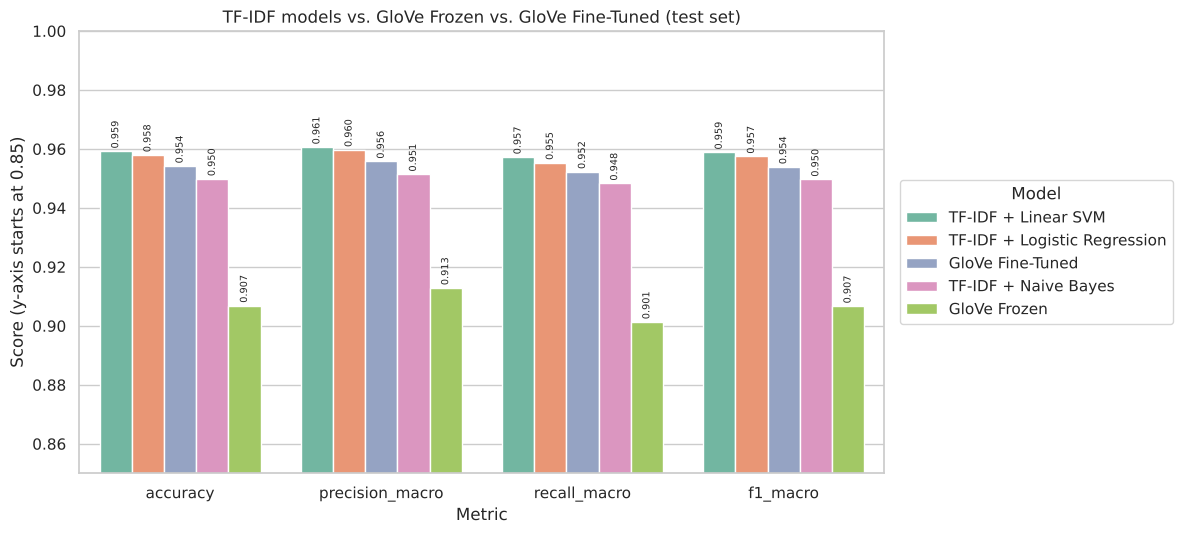

In [17]:
all_results = pd.concat([tfidf_results, glove_results]).sort_values(["f1_macro", "accuracy"], ascending=False)
display(all_results[["accuracy", "precision_macro", "recall_macro", "f1_macro", "fit_seconds"]].round(4))

all_results.round(4).to_csv(config.REPORTS_DIR / "embeddings_comparison.csv")
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
tidy = all_results[metrics].reset_index().melt(id_vars="model", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.barplot(data=tidy, x="metric", y="score", hue="model", palette="Set2", ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", fontsize=7, rotation=90, padding=2)
ax.set(title="TF-IDF models vs. GloVe Frozen vs. GloVe Fine-Tuned (test set)", xlabel="Metric",
       ylabel="Score (y-axis starts at 0.85)", ylim=(0.85, 1.0))
ax.legend(title="Model", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
fig.savefig(config.OUTPUTS_DIR / "embeddings_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
best_name = evaluate.select_best_model(all_results, config.SELECTION_METRIC)
display(Markdown(f"**Selection metric:** `{config.SELECTION_METRIC}`  \n**Best model overall:** {best_name}  \n"
                 f"**Macro F1:** {all_results.loc[best_name, 'f1_macro']:.4f}  |  "
                 f"**Accuracy:** {all_results.loc[best_name, 'accuracy']:.4f}"))

# Cross-check: do the TF-IDF numbers reproduce Submission 1?
saved = config.REPORTS_DIR / "model_comparison.csv"
if saved.exists():
    old = pd.read_csv(saved, index_col="model")["f1_macro"]
    new = tfidf_results["f1_macro"].rename(lambda n: n.replace("TF-IDF + ", ""))
    diff = (new - old.reindex(new.index)).abs().max()
    print(f"Largest difference in macro F1 to the saved Submission 1 results: {diff:.4f}")

**Selection metric:** `f1_macro`  
**Best model overall:** TF-IDF + Linear SVM  
**Macro F1:** 0.9589  |  **Accuracy:** 0.9592

Largest difference in macro F1 to the saved Submission 1 results: 0.0000


## 11. Additional Analysis

### 11.1 What did fine-tuning change?
For a few words we list the nearest neighbours in the **original GloVe** space and in the **fine-tuned** space (cosine similarity). Fine-tuning changes the vectors with the training signal, so words move towards the vocabulary of the products they co-occur with. Read the lists as an illustration only: rare, product-specific tokens (model codes, sizes) can appear as neighbours.

In [19]:
tuned_matrix = glove_models["GloVe Fine-Tuned"].layers[0].get_weights()[0]
rows = []
for w in glove_neighbours:
    rows.append({"word": w, "GloVe neighbours": ", ".join(glove_neighbours[w]),
                 "fine-tuned neighbours": ", ".join(nearest_words(w, tuned_matrix))})
display(pd.DataFrame(rows).set_index("word"))

moved = np.linalg.norm(tuned_matrix - embedding_matrix, axis=1)[2:]
print(f"Average change of a word vector during fine-tuning: {moved.mean():.3f} "
      f"(average length of a GloVe vector: {np.linalg.norm(embedding_matrix[2:], axis=1).mean():.3f})")

,GloVe neighbours,fine-tuned neighbours
word,,
charger,"rechargeable, turbo, battery, ipod, rx, laptop","wxhxd, 700d, 650d, bionz, in1, cat6"
novel,"novels, fiction, book, adaptation, story, author","novels, comic, wrote, thriller, adaptation, sequel"
cotton,"wool, wheat, corn, silk, textile, grain","wool, polyfill, 32cm, infuser, kurtzy, speical"
cooker,"cookers, stove, casserole, oven, fridge, quart","stove, rack, pot, protec, microtek, aeroslim"


Average change of a word vector during fine-tuning: 2.766 (average length of a GloVe vector: 4.568)


### 11.2 Per-class F1 of all models

In [20]:
per_class = {}
for name, y_pred in {**{"TF-IDF + " + k: v for k, v in tfidf_predictions.items()}, **glove_predictions}.items():
    per_class[name] = evaluate.per_class_report(y_test, y_pred, LABELS)["f1-score"].loc[LABELS]
display(pd.DataFrame(per_class).round(4).T)

,Electronics,Household,Books,Clothing & Accessories
TF-IDF + Naive Bayes,0.9311,0.9498,0.9454,0.9722
TF-IDF + Logistic Regression,0.9394,0.9593,0.9528,0.9783
TF-IDF + Linear SVM,0.9426,0.9601,0.9535,0.9792
GloVe Frozen,0.8690,0.9031,0.9251,0.9295
GloVe Fine-Tuned,0.9350,0.9548,0.9471,0.9787


### 11.3 Correct and incorrect predictions (best GloVe model)
Random test samples, text shortened to 220 characters.

In [21]:
best_glove = glove_results["f1_macro"].idxmax()
correct, wrong = evaluate.classification_examples(X_test, y_test, glove_predictions[best_glove], n=5, seed=RANDOM_SEED)
display(Markdown(f"**Correctly classified ({best_glove})**")); display(correct)
display(Markdown(f"**Misclassified ({best_glove})**")); display(wrong)
pair = evaluate.most_confused_pair(y_test, glove_predictions[best_glove], LABELS)
if pair:
    print(f"Most frequent confusion of {best_glove}: true '{pair[0]}' predicted as '{pair[1]}' ({pair[2]} test samples)")

**Correctly classified (GloVe Fine-Tuned)**

,description,true,predicted
0,Raptasripod-3110 402 inch Portable Camera Tripod with Three-Dimensional Head for All Cameras Camcorders with Mobile ...,Electronics,Electronics
1,"Krystle Women's Woolen Hand Gloves (Multicolour, Free Size) Fall in love with the soft texture of the fabric. Your s...",Clothing & Accessories,Clothing & Accessories
2,ABS Detachable Portable Toilet Stool Prevent Constipation Footstool Correct Position for Defecation- 53.5 * 32.5 * 1...,Household,Household
3,Ethical Hacking and Penetration Testing Guide About the Author Rafay Baloch is the founder and owner of RHA Infosec....,Books,Books
4,"Ekan Sun Hat with Long Brim, Summer Fedora Hat for Women 30 Gram Pack of 1 Hats For Women & Girls 100% Brand New and...",Clothing & Accessories,Clothing & Accessories


**Misclassified (GloVe Fine-Tuned)**

,description,true,predicted
0,Harissons Sleep Sac 225cm Sleeping Mat for Trekking Camping Hiking - Sleeping Bag for Adults and Kids (Black Red),Clothing & Accessories,Books
1,SPORTO FITNESS™ Heavy Duty STANDERD Curved Flat bench MODEL:1220 The shipping process for this item follows dispatch...,Household,Books
2,PNP Bnc Connectors Screws for CCTV Camera (Green) - Pack of 10 Pcs These superior quality multipurpose BnC connector...,Electronics,Household
3,One Day at Horrorland (Goosebumps - 16),Books,Electronics
4,Red Hat Linux - Administrator,Books,Clothing & Accessories


Most frequent confusion of GloVe Fine-Tuned: true 'Books' predicted as 'Household' (56 test samples)


## 12. Example Predictions
The six descriptions are **illustrative examples written for this demonstration**. They are *not* dataset records and say nothing about model quality.

In [22]:
from src.predict import EXAMPLE_DESCRIPTIONS
titles = list(EXAMPLE_DESCRIPTIONS)
example_seq = embeddings.texts_to_sequences([clean_text(t) for t in EXAMPLE_DESCRIPTIONS.values()], word_index)
table = {"example (illustrative)": titles}
for name, model in glove_models.items():
    table[name] = embeddings.predict_labels(model, example_seq, LABELS)
display(pd.DataFrame(table))

probabilities = glove_models["GloVe Fine-Tuned"].predict(example_seq, verbose=0)
display(Markdown("**Class probabilities of GloVe Fine-Tuned**"))
display(pd.DataFrame(probabilities, index=titles, columns=LABELS).round(3))

,example (illustrative),GloVe Frozen,GloVe Fine-Tuned
0,Wireless headphones,Electronics,Household
1,Cookware set,Household,Household
2,Novel,Books,Books
3,Cotton t-shirt,Clothing & Accessories,Clothing & Accessories
4,Smart watch,Electronics,Electronics
5,Bed sheet,Household,Household


**Class probabilities of GloVe Fine-Tuned**

,Electronics,Household,Books,Clothing & Accessories
Wireless headphones,0.472,0.528,0.0,0.0
Cookware set,0.000,1.000,0.0,0.0
Novel,0.000,0.000,1.0,0.0
Cotton t-shirt,0.000,0.000,0.0,1.0
Smart watch,1.000,0.000,0.0,0.0
Bed sheet,0.000,1.000,0.0,0.0


## 13. Conclusions

In [23]:
ranking = all_results["f1_macro"]
tfidf_best = tfidf_results["f1_macro"].idxmax()
frozen, tuned = glove_results.loc["GloVe Frozen"], glove_results.loc["GloVe Fine-Tuned"]
lines = [
    "- **Ranking by macro F1 (test set):** " + ", ".join(f"{n} ({v:.4f})" for n, v in ranking.items()) + ".",
    f"- **Fine-tuning vs frozen:** macro F1 changes from {frozen['f1_macro']:.4f} to {tuned['f1_macro']:.4f} "
    f"({tuned['f1_macro'] - frozen['f1_macro']:+.4f}); accuracy from {frozen['accuracy']:.4f} to {tuned['accuracy']:.4f}.",
    f"- **GloVe vs TF-IDF:** the best GloVe model ({best_glove}, {glove_results.loc[best_glove, 'f1_macro']:.4f}) differs from the best "
    f"TF-IDF model ({tfidf_best}, {tfidf_results.loc[tfidf_best, 'f1_macro']:.4f}) by "
    f"{glove_results.loc[best_glove, 'f1_macro'] - tfidf_results.loc[tfidf_best, 'f1_macro']:+.4f} macro F1.",
    f"- **Training time:** frozen {frozen['fit_seconds']:.0f} s, fine-tuned {tuned['fit_seconds']:.0f} s, "
    f"TF-IDF models {tfidf_results['fit_seconds'].min():.0f}-{tfidf_results['fit_seconds'].max():.0f} s (this CPU).",
    f"- **Fit to the training data:** GloVe Fine-Tuned reaches {glove_histories['GloVe Fine-Tuned']['accuracy'][-1]:.4f} training accuracy "
    f"but {tuned['accuracy']:.4f} test accuracy; GloVe Frozen reaches {glove_histories['GloVe Frozen']['accuracy'][-1]:.4f} "
    f"training and {frozen['accuracy']:.4f} test accuracy.",
    f"- **Best model overall:** {best_name}.",
]
display(Markdown("\n".join(lines)))

- **Ranking by macro F1 (test set):** TF-IDF + Linear SVM (0.9589), TF-IDF + Logistic Regression (0.9574), GloVe Fine-Tuned (0.9539), TF-IDF + Naive Bayes (0.9496), GloVe Frozen (0.9067).
- **Fine-tuning vs frozen:** macro F1 changes from 0.9067 to 0.9539 (+0.0472); accuracy from 0.9069 to 0.9542.
- **GloVe vs TF-IDF:** the best GloVe model (GloVe Fine-Tuned, 0.9539) differs from the best TF-IDF model (TF-IDF + Linear SVM, 0.9589) by -0.0050 macro F1.
- **Training time:** frozen 12 s, fine-tuned 52 s, TF-IDF models 6-10 s (this CPU).
- **Fit to the training data:** GloVe Fine-Tuned reaches 0.9973 training accuracy but 0.9542 test accuracy; GloVe Frozen reaches 0.9036 training and 0.9069 test accuracy.
- **Best model overall:** TF-IDF + Linear SVM.

**How to read these results.** Compare the numbers with the two questions of this assignment:
(1) *Does fine-tuning help compared with keeping GloVe frozen?* The frozen model can only learn a linear rule on the averaged vector, whereas the fine-tuned model may also change the word vectors themselves.
(2) *Do embeddings beat TF-IDF here?* The comparison above answers this for this dataset only.

**Possible explanations (not tested in this notebook).** GloVe was trained on Wikipedia and news, whose language differs from short product listings with brand names and model numbers; fine-tuning can adapt the vectors to this vocabulary. Averaging word vectors ignores word order and treats every word equally, while TF-IDF can give rare, category-specific words (such as *paperback*) a large weight directly.

**Limitations.**
- A single train-test split and a single training run (seed 42) are used; small differences between models may be within random variation.
- Descriptions longer than 150 words are cut, and words outside the 20,000-word vocabulary are treated as unknown.
- The learning rate and the number of epochs were checked on a validation slice of the training data only; no further tuning was done for either approach.
- The fine-tuned model has about 2 million trainable numbers, so it can fit the training data much more closely than the frozen one; compare its training and test accuracy in the conclusions above and look at the diagnostic curves.
- Training times depend on the computer and are only indicative.

**Possible improvements.** Larger GloVe vectors (200d/300d), lower learning rate or early stopping for fine-tuning, a dropout layer, TF-IDF-weighted averaging of the word vectors, combining TF-IDF and embeddings, or a transformer model (optional extensions that were deliberately left out to keep the model simple).